<a href="https://colab.research.google.com/github/harivasan1/Ai-study-assistant/blob/main/house_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Libraries imported successfully!

Dataset created successfully!
   area_sqft  bedrooms  age_years  location_score  price_lakhs
0        600         1         20               3           20
1        800         2         15               4           28
2       1000         2         10               5           35
3       1200         2          8               6           42
4       1500         3          5               7           55

Dataset shape: (25, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   area_sqft       25 non-null     int64
 1   bedrooms        25 non-null     int64
 2   age_years       25 non-null     int64
 3   location_score  25 non-null     int64
 4   price_lakhs     25 non-null     int64
dtypes: int64(5)
memory usage: 1.1 KB

Statistical Summary:
         area_sqft   bedrooms  age_years  locatio

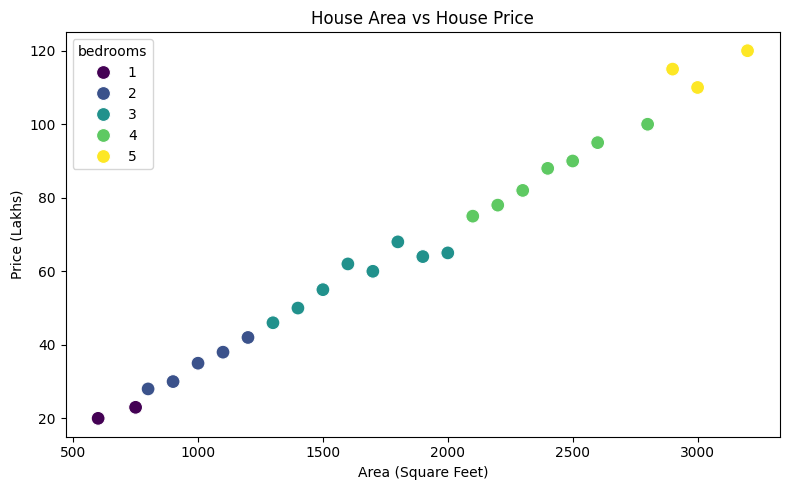


Features selected:
   area_sqft  bedrooms  age_years  location_score
0        600         1         20               3
1        800         2         15               4
2       1000         2         10               5
3       1200         2          8               6
4       1500         3          5               7

Target values:
0    20
1    28
2    35
3    42
4    55
Name: price_lakhs, dtype: int64

Training records: 20
Testing records: 5

Model trained successfully!

Actual vs Predicted Prices:
   Actual Price  Predicted Price
0            90            91.05
1            62            56.75
2            20            20.44
3            82            83.00
4            50            48.71

MODEL EVALUATION
------------------------------
MAE: 1.81 lakhs
MSE: 6.3
RMSE: 2.51 lakhs
R2 Score: 0.99


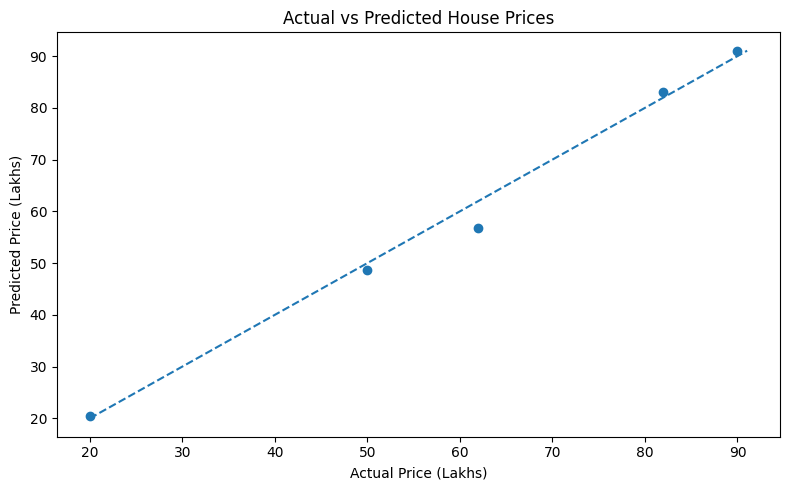


Feature Coefficients:
          Feature  Coefficient
0       area_sqft     0.027612
1        bedrooms     3.271237
2       age_years     1.131343
3  location_score     4.781484

Model Intercept: -36.37

NEW HOUSE PRICE PREDICTION
------------------------------
Area: 1600 square feet
Bedrooms: 3
Property age: 5 years
Location score: 8/10
Predicted price: Rs. 61.54 lakhs

MULTIPLE HOUSE PRICE PREDICTIONS
 area_sqft  bedrooms  age_years  location_score  predicted_price_lakhs
      1000         2         10               5                  33.01
      1800         3          4               8                  65.93
      2500         4          2               9                  91.05

Project completed successfully!


In [ ]:

# ============================================================
# PROJECT: HOUSE PRICE PREDICTION USING MACHINE LEARNING
# Platform: Google Colab
# Algorithm: Linear Regression
# ============================================================

# STEP 1: IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")


# STEP 2: CREATE THE DATASET

data = {
    "area_sqft": [
        600, 800, 1000, 1200, 1500,
        1800, 2000, 2200, 2500, 3000,
        900, 1400, 1700, 2400, 2800,
        1100, 1600, 2100, 2600, 3200,
        750, 1300, 1900, 2300, 2900
    ],

    "bedrooms": [
        1, 2, 2, 2, 3,
        3, 3, 4, 4, 5,
        2, 3, 3, 4, 4,
        2, 3, 4, 4, 5,
        1, 3, 3, 4, 5
    ],

    "age_years": [
        20, 15, 10, 8, 5,
        4, 6, 3, 2, 1,
        12, 7, 9, 3, 2,
        11, 5, 4, 3, 1,
        18, 8, 6, 4, 2
    ],

    "location_score": [
        3, 4, 5, 6, 7,
        8, 7, 8, 9, 10,
        4, 6, 7, 9, 9,
        5, 7, 8, 9, 10,
        3, 6, 7, 8, 10
    ],

    # Illustrative prices in Indian lakhs, not real market data
    "price_lakhs": [
        20, 28, 35, 42, 55,
        68, 65, 78, 90, 110,
        30, 50, 60, 88, 100,
        38, 62, 75, 95, 120,
        23, 46, 64, 82, 115
    ]
}

df = pd.DataFrame(data)

print("\nDataset created successfully!")
print(df.head())

print("\nDataset shape:", df.shape)


# STEP 3: UNDERSTAND THE DATA

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())


# STEP 4: VISUALIZE THE DATA

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="area_sqft",
    y="price_lakhs",
    hue="bedrooms",
    palette="viridis",
    s=100
)

plt.title("House Area vs House Price")
plt.xlabel("Area (Square Feet)")
plt.ylabel("Price (Lakhs)")
plt.tight_layout()
plt.show()


# STEP 5: SELECT FEATURES AND TARGET

X = df[
    [
        "area_sqft",
        "bedrooms",
        "age_years",
        "location_score"
    ]
]

y = df["price_lakhs"]

print("\nFeatures selected:")
print(X.head())

print("\nTarget values:")
print(y.head())


# STEP 6: SPLIT DATA INTO TRAINING AND TESTING SETS

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))


# STEP 7: CREATE AND TRAIN THE MODEL

model = LinearRegression()

model.fit(X_train, y_train)

print("\nModel trained successfully!")


# STEP 8: MAKE TEST PREDICTIONS

y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": np.round(y_pred, 2)
})

print("\nActual vs Predicted Prices:")
print(results)


# STEP 9: EVALUATE MODEL PERFORMANCE

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("\nMODEL EVALUATION")
print("------------------------------")
print("MAE:", round(mae, 2), "lakhs")
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2), "lakhs")
print("R2 Score:", round(r2, 3))


# STEP 10: VISUALIZE ACTUAL VS PREDICTED PRICES

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.tight_layout()
plt.show()


# STEP 11: DISPLAY MODEL COEFFICIENTS

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

print("\nFeature Coefficients:")
print(coefficients)

print("\nModel Intercept:", round(model.intercept_, 2))


# STEP 12: PREDICT THE PRICE OF A NEW HOUSE

new_house = pd.DataFrame([{
    "area_sqft": 1600,
    "bedrooms": 3,
    "age_years": 5,
    "location_score": 8
}])

predicted_price = model.predict(new_house)[0]

print("\nNEW HOUSE PRICE PREDICTION")
print("------------------------------")
print("Area: 1600 square feet")
print("Bedrooms: 3")
print("Property age: 5 years")
print("Location score: 8/10")
print("Predicted price: Rs.",
      round(predicted_price, 2), "lakhs")


# STEP 13: PREDICT MULTIPLE NEW HOUSES

new_houses = pd.DataFrame([
    {
        "area_sqft": 1000,
        "bedrooms": 2,
        "age_years": 10,
        "location_score": 5
    },
    {
        "area_sqft": 1800,
        "bedrooms": 3,
        "age_years": 4,
        "location_score": 8
    },
    {
        "area_sqft": 2500,
        "bedrooms": 4,
        "age_years": 2,
        "location_score": 9
    }
])

multiple_predictions = model.predict(new_houses)

new_houses["predicted_price_lakhs"] = np.round(
    multiple_predictions, 2
)

print("\nMULTIPLE HOUSE PRICE PREDICTIONS")
print(new_houses.to_string(index=False))


# STEP 14: FINISH

print("\nProject completed successfully!")
